## ⚠️ Multi-Class Addendum

The `load_digits` dataset has **10 classes** (digits 0–9), not 2. This changes
how some metrics are interpreted.

### What is still well-defined
- **Confusion matrix** — now a 10×10 table. Rows = true digit, columns = predicted digit.
  Diagonal = correct, off-diagonal = specific confusions (e.g., 3↔5, 4↔9 are classic).
- **Accuracy** — fraction of correct predictions. Still meaningful here because
  the 10 classes are roughly balanced (~180 samples each).

### What needs an averaging strategy
Precision, recall (sensitivity), specificity, and F1 are **per-class** quantities
in multi-class problems. To get a single number you must average:

- **Macro-average** — compute the metric for each class independently, then take
  the unweighted mean. Treats every class equally. Good when classes are balanced.
- **Weighted-average** — same, but weighted by class support (number of true
  samples). Good when classes are imbalanced.
- **Micro-average** — pool all TP/FP/FN across classes, then compute the metric
  once. For single-label multi-class, micro-F1 = micro-precision = micro-recall
  = **accuracy**. Not very informative on its own.

In this notebook we report **macro** and **weighted** versions. "Sensitivity"
is reported as `recall_macro` (mean per-class true-positive rate). "Specificity"
is reported as the mean per-class true-negative rate, computed one-vs-rest.

### What is NOT defined and therefore dropped
- **Single AUC value** — AUC requires a binary positive/negative split. For 10
  classes you would need to reduce the problem (One-vs-Rest → 10 AUCs, or
  One-vs-One → 45 AUCs). We deliberately skip this to avoid misleading numbers.
- **ROC curve** — a single 2-D ROC curve does not exist for 10 classes. Plotting
  `roc_curve` on multi-class labels raises an error in Scikit-Learn.

### Cross-validation (unchanged)
`StratifiedKFold` still works — it preserves the 10-class proportions in every
fold. The **CV error** is still `1 − CV accuracy`, averaged over the 5 folds,
and remains an out-of-sample estimate of generalization.

### Generalization analysis (unchanged)
The error learning curves still apply. For each classifier we plot
**training error** and **CV error** (both = 1 − accuracy, multi-class) against
the number of training samples. A large gap = overfitting. Both errors high and
close = underfitting. Both low and converging = good fit.

Loading load_digits...
Dataset shape: (1797, 64)
Class distribution:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64
Train: 1437 | Test: 360

Running 5-fold cross-validation (multi-class)...
  → Logistic Regression
  → Random Forest
  → Naive Bayes
  → K-Nearest Neighbors
  → SVM (RBF)
  → MLP (Neural Net)
  → XGBoost

=== Cross-Validation Results (multi-class) ===
              Model  Accuracy  Sensitivity (macro)  Sensitivity (weighted)  Specificity (macro)  Precision (macro)  F1 (macro)  F1 (weighted)
          SVM (RBF)  0.981211             0.981228                0.981211             0.997912           0.981969    0.981211       0.981193
      Random Forest  0.976338             0.976274                0.976338             0.997371           0.976684    0.976227       0.976278
   MLP (Neural Net)  0.975644             0.975559                0.975644             0.997293           0.976402    0.975576       0.975

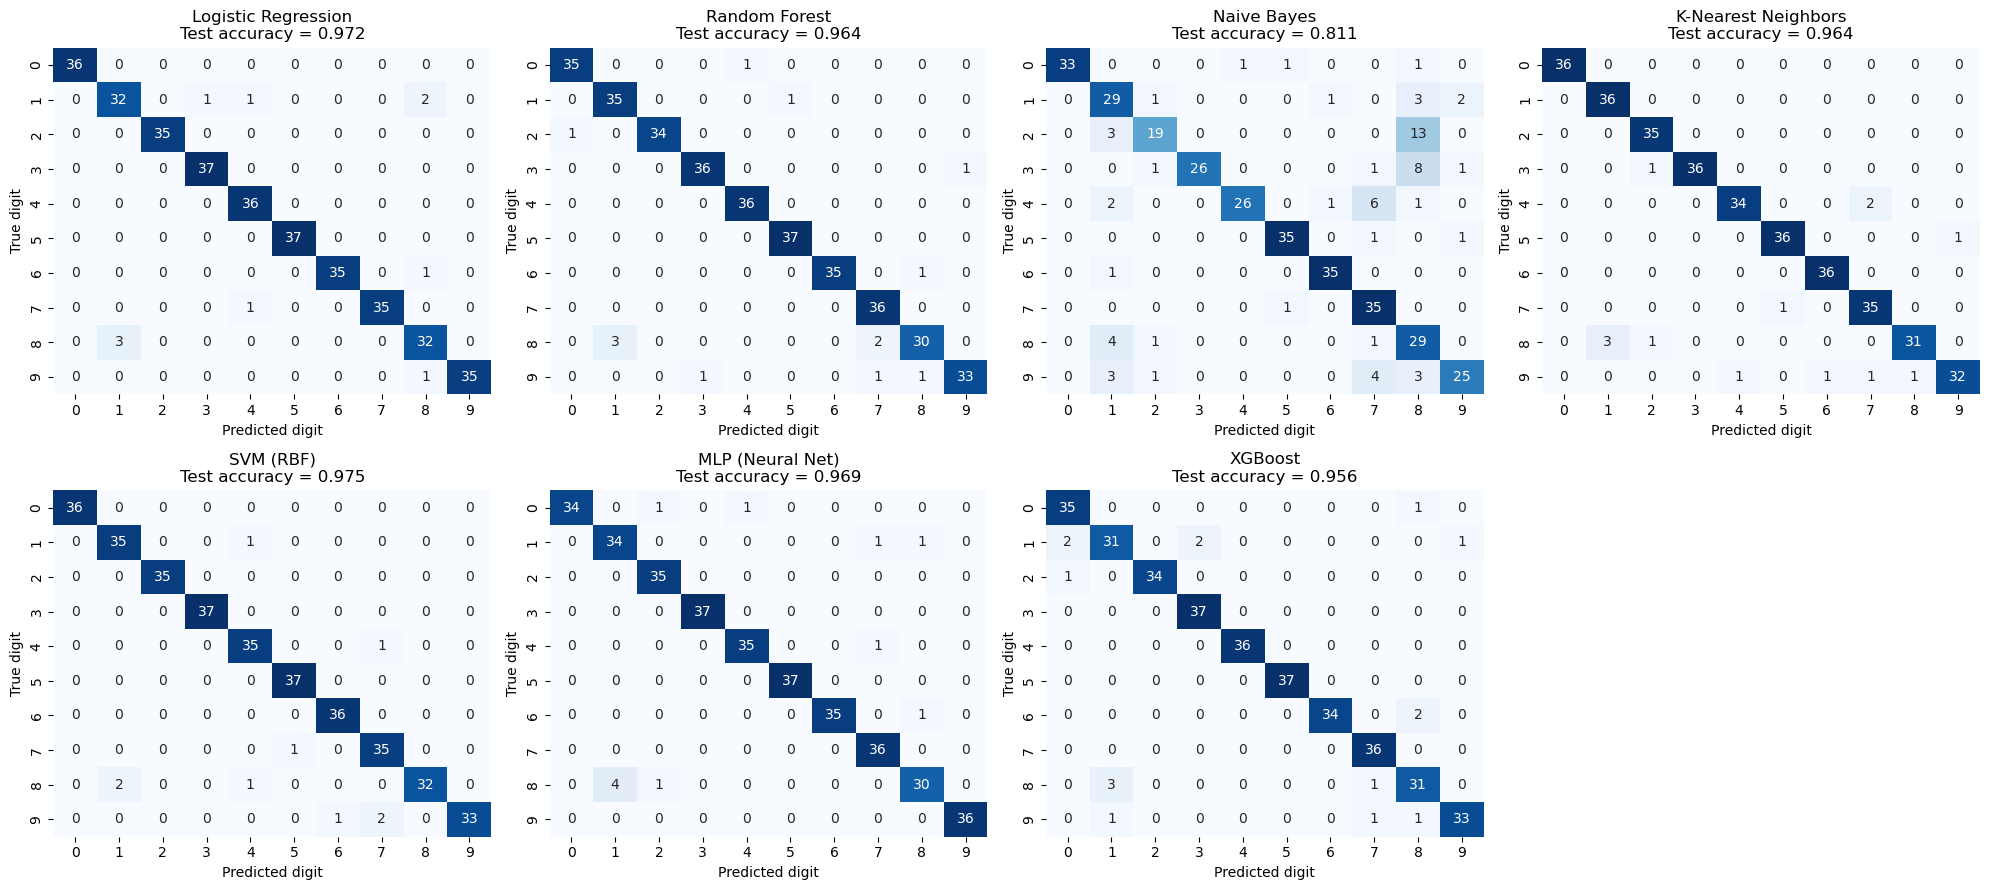


Generating error learning curves (multi-class)...
Logistic Regression: train err = 0.000 | CV err = 0.031 | gap = +0.031
Random Forest: train err = 0.000 | CV err = 0.024 | gap = +0.024
Naive Bayes: train err = 0.148 | CV err = 0.178 | gap = +0.030
K-Nearest Neighbors: train err = 0.015 | CV err = 0.024 | gap = +0.009
SVM (RBF): train err = 0.002 | CV err = 0.019 | gap = +0.016
MLP (Neural Net): train err = 0.000 | CV err = 0.026 | gap = +0.026
XGBoost: train err = 0.000 | CV err = 0.035 | gap = +0.035


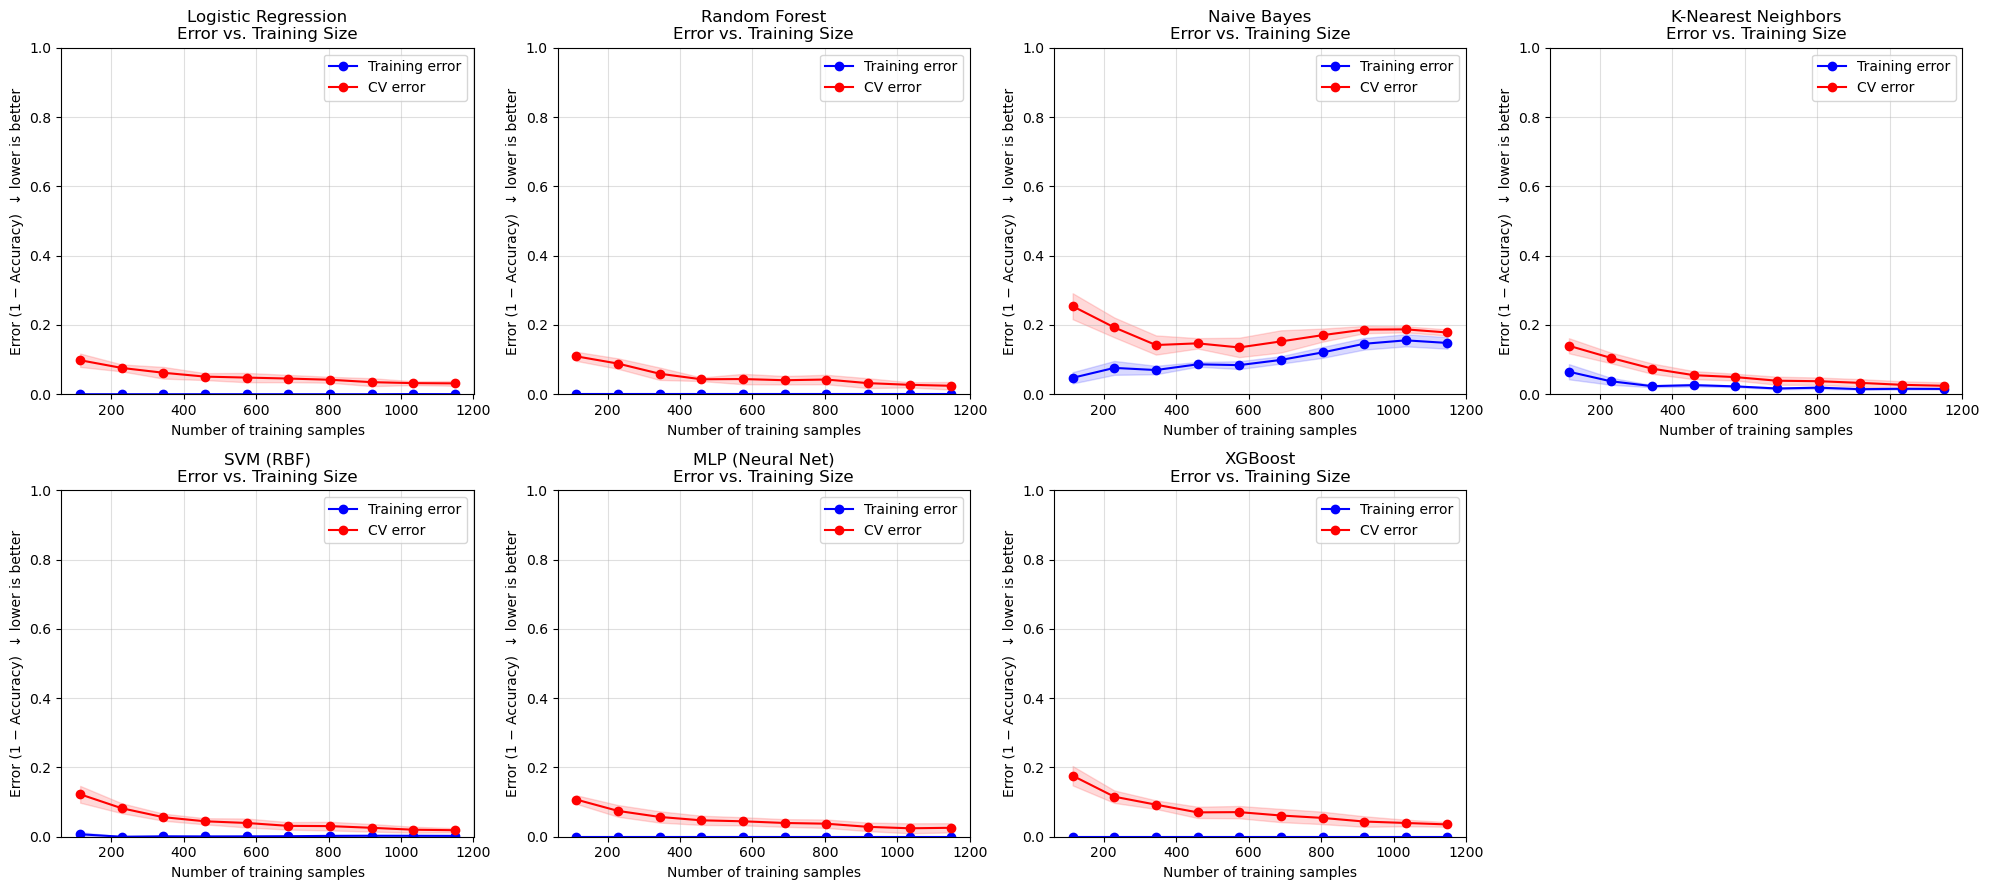


Interpretation:
  - Large positive gap (CV err >> train err)  -> OVERFITTING
  - Both errors high and close together       -> UNDERFITTING
  - Both low and converging                   -> GOOD FIT

Analysis Complete.


In [4]:
# ==============================================================================
# MULTI-CLASS CLASSIFICATION ON load_digits (10 classes: digits 0–9)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, recall_score, precision_score,
                             f1_score, make_scorer)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed — skipping XGBClassifier.")

# ==============================================================================
# 1. DATA LOADING
# ==============================================================================
print("Loading load_digits...")
digits = load_digits()
X = digits.data          # (1797, 64) — 8×8 pixel images, flattened
y = digits.target        # labels 0–9

print(f"Dataset shape: {X.shape}")
print(f"Class distribution:\n{pd.Series(y).value_counts().sort_index()}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

# ==============================================================================
# 2. CLASSIFIERS
# ==============================================================================
classifiers = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, multi_class='auto', random_state=42))
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', random_state=42))
    ]),
    'MLP (Neural Net)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000, random_state=42))
    ]),
}

if HAS_XGB:
    classifiers['XGBoost'] = XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=4,
        use_label_encoder=False, eval_metric='mlogloss', random_state=42
    )

# ==============================================================================
# 3. CROSS-VALIDATION — multi-class-safe scorers only (NO AUC)
# ==============================================================================
# Sensitivity == per-class recall; average with macro & weighted.
# Specificity is NOT a built-in scorer for multi-class; compute per-class
# one-vs-rest TN rate and average. Micro-average of recall equals accuracy.

def specificity_macro(y_true, y_pred):
    """Mean one-vs-rest specificity across all classes."""
    labels = np.unique(np.concatenate([y_true, y_pred]))
    specs = []
    for c in labels:
        yt = (y_true == c)
        yp = (y_pred == c)
        tn = np.sum((~yt) & (~yp))
        fp = np.sum((~yt) & (yp))
        specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    return float(np.mean(specs))

scoring = {
    'accuracy':        'accuracy',
    'recall_macro':    'recall_macro',        # sensitivity, macro
    'recall_weighted': 'recall_weighted',     # sensitivity, weighted
    'precision_macro': 'precision_macro',
    'f1_macro':        'f1_macro',
    'f1_weighted':     'f1_weighted',
    'specificity':     make_scorer(specificity_macro),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
print("\nRunning 5-fold cross-validation (multi-class)...")
for name, model in classifiers.items():
    print(f"  → {name}")
    cv_results = cross_validate(model, X_train, y_train, cv=cv,
                                scoring=scoring, n_jobs=-1)
    results.append({
        'Model':              name,
        'Accuracy':           cv_results['test_accuracy'].mean(),
        'Sensitivity (macro)':   cv_results['test_recall_macro'].mean(),
        'Sensitivity (weighted)': cv_results['test_recall_weighted'].mean(),
        'Specificity (macro)':   cv_results['test_specificity'].mean(),
        'Precision (macro)':  cv_results['test_precision_macro'].mean(),
        'F1 (macro)':         cv_results['test_f1_macro'].mean(),
        'F1 (weighted)':      cv_results['test_f1_weighted'].mean(),
    })

results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("\n=== Cross-Validation Results (multi-class) ===")
print(results_df.to_string(index=False))

# ==============================================================================
# 4. TEST-SET EVALUATION — 10×10 confusion matrices + per-class report
# ==============================================================================
n_models = len(classifiers)
n_cols = 4
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for i, (name, model) in enumerate(classifiers.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                ax=axes[i], cbar=False,
                xticklabels=range(10), yticklabels=range(10))
    axes[i].set_title(f'{name}\nTest accuracy = {accuracy_score(y_test, y_pred):.3f}')
    axes[i].set_xlabel('Predicted digit')
    axes[i].set_ylabel('True digit')

    print(f"\n--- {name} (Test Set) ---")
    print(classification_report(y_test, y_pred, digits=3))

    train_acc = model.score(X_train, y_train)
    test_acc  = model.score(X_test, y_test)
    print(f"Train acc = {train_acc:.4f} | Test acc = {test_acc:.4f} | "
          f"Generalization gap (acc) = {train_acc - test_acc:+.4f}")

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. (DROPPED) ROC / AUC SECTION
# ==============================================================================
# A single AUC and a single ROC curve are not defined for 10-class problems.
# Reducing to One-vs-Rest would produce 10 separate AUCs, which is outside the
# scope of this benchmark. This section is intentionally omitted.

# ==============================================================================
# 6. GENERALIZATION ANALYSIS — ERROR vs. NUMBER OF TRAINING SAMPLES
# ==============================================================================
print("\nGenerating error learning curves (multi-class)...")
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

train_sizes = np.linspace(0.1, 1.0, 10)

for i, (name, model) in enumerate(classifiers.items()):
    train_sizes_abs, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes, cv=cv,
        scoring='accuracy', n_jobs=-1, random_state=42
    )

    # Convert accuracy → error (lower is better)
    train_err_mean = 1.0 - train_scores.mean(axis=1)
    train_err_std  = train_scores.std(axis=1)
    val_err_mean   = 1.0 - val_scores.mean(axis=1)
    val_err_std    = val_scores.std(axis=1)

    axes[i].plot(train_sizes_abs, train_err_mean, 'o-', color='blue', label='Training error')
    axes[i].fill_between(train_sizes_abs,
                         train_err_mean - train_err_std,
                         train_err_mean + train_err_std,
                         alpha=0.15, color='blue')

    axes[i].plot(train_sizes_abs, val_err_mean, 'o-', color='red', label='CV error')
    axes[i].fill_between(train_sizes_abs,
                         val_err_mean - val_err_std,
                         val_err_mean + val_err_std,
                         alpha=0.15, color='red')

    axes[i].set_title(f'{name}\nError vs. Training Size')
    axes[i].set_xlabel('Number of training samples')
    axes[i].set_ylabel('Error (1 − Accuracy)  ↓ lower is better')
    axes[i].set_ylim(0, 1)
    axes[i].legend(loc='best')
    axes[i].grid(True, alpha=0.4)

    gap = val_err_mean[-1] - train_err_mean[-1]
    print(f"{name}: train err = {train_err_mean[-1]:.3f} | "
          f"CV err = {val_err_mean[-1]:.3f} | gap = {gap:+.3f}")

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("  - Large positive gap (CV err >> train err)  -> OVERFITTING")
print("  - Both errors high and close together       -> UNDERFITTING")
print("  - Both low and converging                   -> GOOD FIT")
print("\nAnalysis Complete.")